In [39]:
import requests

URL= "https://www.scrapethissite.com/pages/simple/"

res= requests.get(URL)

In [40]:
if res.status_code== 200:
    print(res.headers)


with open("Scraped data/data1.html","w", encoding="utf-8") as f:
    f.write(res.text)

{'Date': 'Thu, 25 Jun 2026 11:04:50 GMT', 'Content-Type': 'text/html; charset=utf-8', 'Transfer-Encoding': 'chunked', 'Connection': 'keep-alive', 'Nel': '{"report_to":"heroku-nel","response_headers":["Via"],"max_age":3600,"success_fraction":0.01,"failure_fraction":0.1}', 'Report-To': '{"group":"heroku-nel","endpoints":[{"url":"https://nel.heroku.com/reports?s=tavs3zRbeC3rezzSlypqMa1oQAtGvKK3BSzgZS7eYCc%3D\\u0026sid=67ff5de4-ad2b-4112-9289-cf96be89efed\\u0026ts=1782385489"}],"max_age":3600}', 'Reporting-Endpoints': 'heroku-nel="https://nel.heroku.com/reports?s=tavs3zRbeC3rezzSlypqMa1oQAtGvKK3BSzgZS7eYCc%3D&sid=67ff5de4-ad2b-4112-9289-cf96be89efed&ts=1782385489"', 'Server': 'cloudflare', 'Via': '1.1 heroku-router', 'Cf-Cache-Status': 'DYNAMIC', 'Content-Encoding': 'zstd', 'CF-RAY': 'a1137e5d8d6b5f69-SIN', 'alt-svc': 'h3=":443"; ma=86400'}


In [43]:
from bs4 import BeautifulSoup #here BeautifulSoup is a class

with open("Scraped data/data1.html","r",encoding="utf-8") as f:
    html_content = f.read()

soup = BeautifulSoup(html_content,"lxml") #here soup is a object ,and is called so because its very messy

In [25]:
all_h3 =soup.find_all("h3") # to access all the countries

all_countries= []

for i in all_h3:
    name = i.get_text(strip=True) # will extract all the countries name only and also remove the spaces since strip= true
    population= i.find_next("div").select_one("span.country-population").get_text(strip=True) #as the population was stored in next div, it will go there and select first criteria in span section,purify it and will remove the spaces

    all_countries.append([name,population])

In [27]:
import pandas as pd

df= pd.DataFrame(all_countries, columns=["name","population"])

In [74]:
df.to_csv("Scraped data/cleaned_data.csv", index=False)

In [86]:
# fetching data from quotes scraping websites each page and storing it

page_count= 1

while True:
    URL = f"https://quotes.toscrape.com/page/{page_count}/"
    res= requests.get(URL)

    soup= BeautifulSoup(res.text,"lxml")
    quotes= soup.select("div.quote") # this will only choose those qoutes which has quote as class in there div

    
    if not quotes:
        print("no valid page any more")
        break

    with open(f"Scraped data/quotes_data{page_count}.html","w",encoding="utf-8") as f:
        f.write(res.text)
        print(f"Downloaded data from page {page_count}")

    page_count= page_count + 1


Downloaded data from page 1
Downloaded data from page 2
Downloaded data from page 3
Downloaded data from page 4
Downloaded data from page 5
Downloaded data from page 6
Downloaded data from page 7
Downloaded data from page 8
Downloaded data from page 9
Downloaded data from page 10
no valid page any more


In [21]:
# extracting usefull info from all the pages
from bs4 import BeautifulSoup
page_count=1
life_quotes=[]
while page_count<11:
    with open(f"Scraped data/quotes_data{page_count}.html","r",encoding="utf-8") as f:
        q_data = f.read()

    soup=BeautifulSoup(q_data,"lxml")
    all_quotes= soup.select("div.quote")

    for q in all_quotes:
        all_tags=[]

        for t in q.select(".tags a.tag"):
            all_tags.append(t.get_text())
            
        if "life" in all_tags:
            text= q.select("span.text")
            name= q.select_one("small.author")
            life_quotes.append([text,name])
    page_count+=1

print(life_quotes)

[[[<span class="text" itemprop="text">“There are only two ways to live your life. One is as though nothing is a miracle. The other is as though everything is a miracle.”</span>], <small class="author" itemprop="author">Albert Einstein</small>], [[<span class="text" itemprop="text">“It is better to be hated for what you are than to be loved for what you are not.”</span>], <small class="author" itemprop="author">André Gide</small>], [[<span class="text" itemprop="text">“This life is what you make it. No matter what, you're going to mess up sometimes, it's a universal truth. But the good part is you get to decide how you're going to mess it up. Girls will be your friends - they'll act like it anyway. But just remember, some come, some go. The ones that stay with you through everything - they're your true best friends. Don't let go of them. Also remember, sisters make the best friends in the world. As for lovers, well, they'll come and go too. And baby, I hate to say it, most of them - act

In [29]:
df= pd.DataFrame(life_quotes)

In [31]:
df

,0,1
0,[[“There are only two ways to live your life. ...,[Albert Einstein]
1,[[“It is better to be hated for what you are t...,[André Gide]
2,[[“This life is what you make it. No matter wh...,[Marilyn Monroe]
3,"[[“I may not have gone where I intended to go,...",[Douglas Adams]
4,"[[“Good friends, good books, and a sleepy cons...",[Mark Twain]
5,[[“Life is what happens to us while we are mak...,[Allen Saunders]
6,"[[“Today you are You, that is truer than true....",[Dr. Seuss]
7,[[“Life is like riding a bicycle. To keep your...,[Albert Einstein]
8,[[“Life isn't about finding yourself. Life is ...,[George Bernard Shaw]
9,[[“Finish each day and be done with it. You ha...,[Ralph Waldo Emerson]


In [10]:
import matplotlib.pyplot as plt

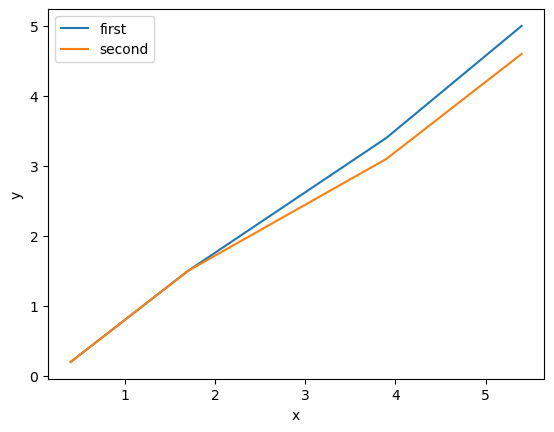

In [67]:
df2= pd.read_csv("IRIS.csv")
df3= df2.drop(columns="species")
x= df3.iloc[5]
y= df3.iloc[7]
z= df3.iloc[3]

plt.xlabel("x")
plt.ylabel("y")


plt.plot(x,y,label="first")
plt.plot(x,z,label="second")

plt.legend()


In [28]:
days=["mon","tue","wed","thu","fri"]

cities=["Delhi", "Tokyo", "Agra","Ayodhya"]

temp=[
    [23,24,22,25,26],
    [23,45,46,47,23],
    [53,52,51,23,27],
    [23,24,22,25,26]
]

Text(0.5, 1.0, 'Ayodhya')

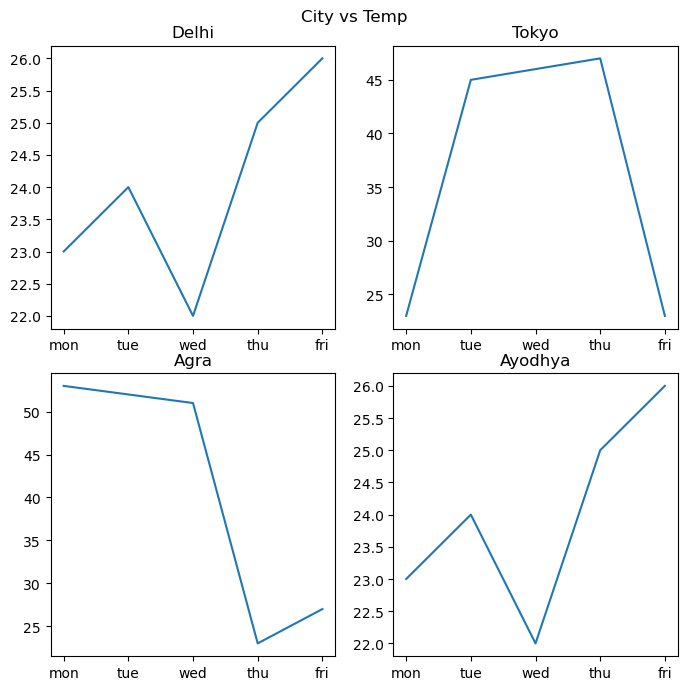

In [32]:
fig ,ax= plt.subplots(2,2,figsize=(7,7))

fig.suptitle("City vs Temp")
fig.tight_layout()

ax[0][0].plot(days,temp[0])
ax[0][0].set_title(cities[0])

ax[0][1].plot(days,temp[1])
ax[0][1].set_title(cities[1])

ax[1][0].plot(days,temp[2])
ax[1][0].set_title(cities[2])

ax[1][1].plot(days,temp[3])
ax[1][1].set_title(cities[3])

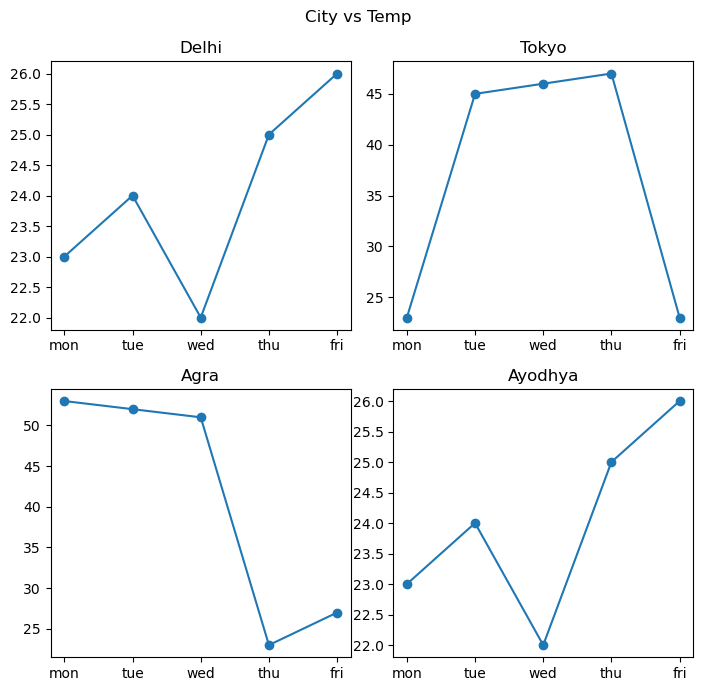

In [34]:
# can also be done by
fig ,axes= plt.subplots(2,2,figsize=(7,7))

axes=axes.flatten() #converted to 1d array
for i,ax in enumerate(axes): # here enumerate will return the index and value at that idx both.
    ax.plot(days,temp[i],marker='o')
    ax.set_title(cities[i])
    
fig.suptitle("City vs Temp")
fig.tight_layout()


In [7]:
# seaborn
import matplotlib.pyplot as plt
import seaborn as sns


In [9]:
tips= sns.load_dataset("tips")

In [11]:
print(tips.head())

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


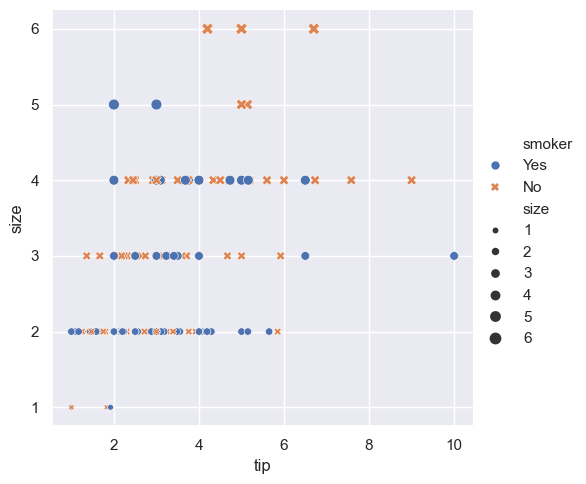

In [19]:
sns.set_theme() #currently showing default theme

sns.relplot(
    data= tips, #here data will get all the information at once ,no need to mention seperately
    x="tip",
    y="size",
    hue= "smoker", #this will colour code the data points of x/y on bacis of a third value with atomatic legend
    size= "size",  #showing different value with there sizes
    style="smoker" # wil give different style for values acording to smoker 

)

In [25]:
import numpy as np

data=np.random.normal(loc=70, scale=10, size=200)

<Axes: ylabel='Count'>

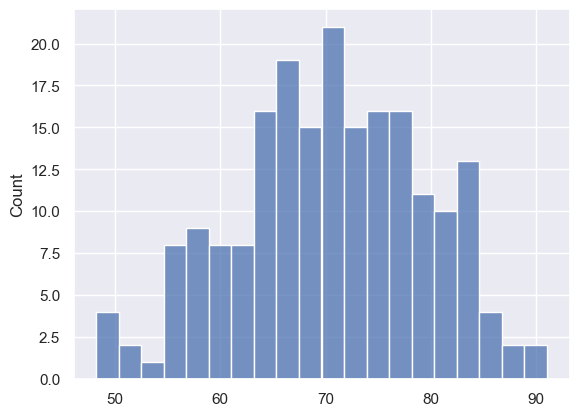

In [49]:
sns.histplot(
    data= data,
    bins=20
    
)

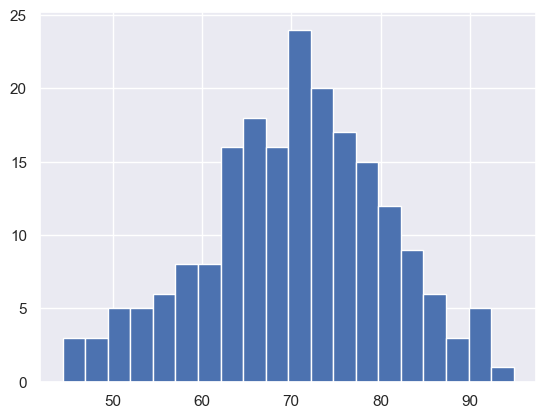

In [43]:
import numpy as np
scores = np.random.normal(loc=70, scale=10, size=200)


plt.hist(scores, bins=20)

# Plot mean line


plt.show() 

In [53]:
d1=sns.load_dataset("penguins")

<Axes: xlabel='flipper_length_mm', ylabel='body_mass_g'>

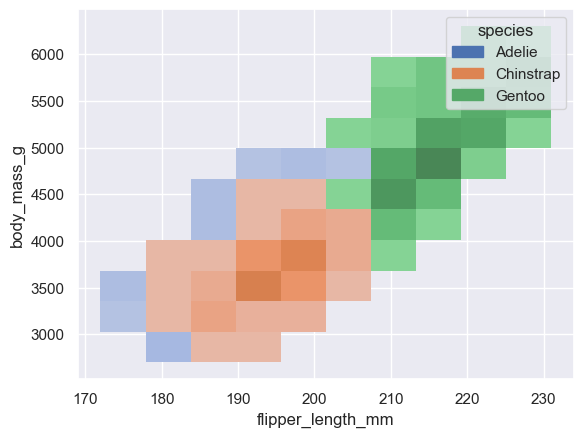

In [59]:
sns.histplot(
    data=d1,
    x="flipper_length_mm",
    y="body_mass_g",
    hue="species"
)

In [63]:
d2=sns.load_dataset("tips")

C:\Users\VICTUS\AppData\Local\Temp\ipykernel_8508\1218229130.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  median= d2.groupby("day")["total_bill"].median()


day
Thur    16.20
Fri     15.38
Sat     18.24
Sun     19.63
Name: total_bill, dtype: float64


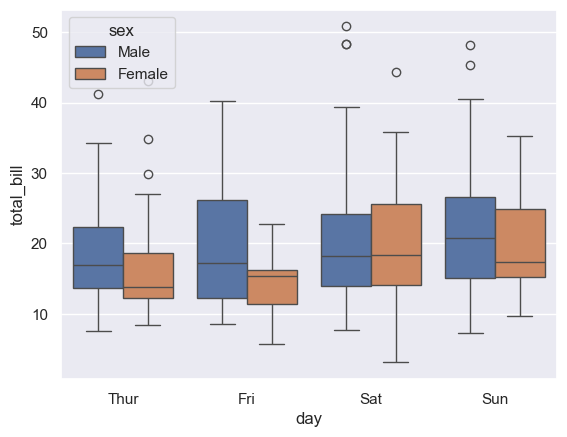

In [100]:
sns.boxplot(
    data=d2,
    y="total_bill",
    x="day",
    hue="sex",
)
median= d2.groupby("day")["total_bill"].median()
print(median)

<Axes: xlabel='total_bill', ylabel='tip'>

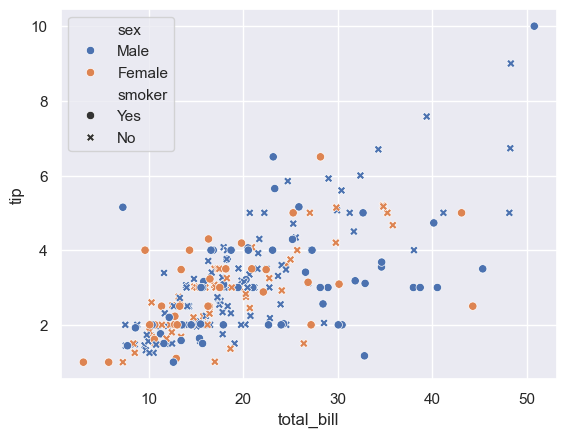

In [118]:
sns.scatterplot(
    data= d2,
    x="total_bill",
    y= "tip",
    hue= "sex",
    style="smoker"
    
)

In [120]:
d2.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [132]:
d3= d2.pivot_table(observed=False,index="day",columns="time",values="tip",aggfunc="mean")
d3.head()

time,Lunch,Dinner
day,,
Thur,2.767705,3.000000
Fri,2.382857,2.940000
Sat,NaN,2.993103
Sun,NaN,3.255132


<Axes: xlabel='time', ylabel='day'>

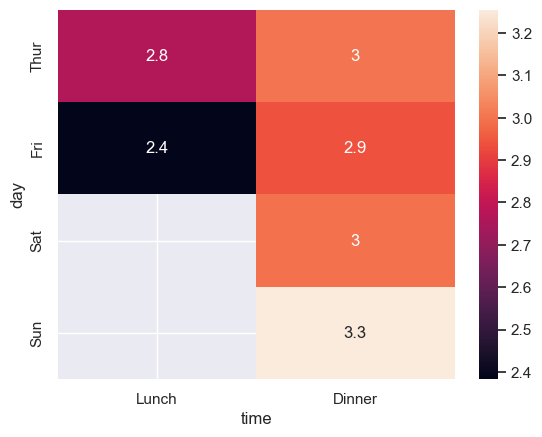

In [138]:
sns.heatmap(
    data= d3,
    annot=True
)

In [136]:
sns.heatmap?

Signature:
sns.heatmap(
    data,
    *,
    vmin=None,
    vmax=None,
    cmap=None,
    center=None,
    robust=False,
    annot=None,
    fmt='.2g',
    annot_kws=None,
    linewidths=0,
    linecolor='white',
    cbar=True,
    cbar_kws=None,
    cbar_ax=None,
    square=False,
    xticklabels='auto',
    yticklabels='auto',
    mask=None,
    ax=None,
    **kwargs,
)
Docstring:
Plot rectangular data as a color-encoded matrix.

This is an Axes-level function and will draw the heatmap into the
currently-active Axes if none is provided to the ``ax`` argument.  Part of
this Axes space will be taken and used to plot a colormap, unless ``cbar``
is False or a separate Axes is provided to ``cbar_ax``.

Parameters
----------
data : rectangular dataset
    2D dataset that can be coerced into an ndarray. If a Pandas DataFrame
    is provided, the index/column information will be used to label the
    columns and rows.
vmin, vmax : floats, optional
    Values to anchor the colormap, otherwise